# Классификация CIFAR 10 с CNN

PyTorch CNN с остаточной связью, цикл обучения на GPU, сравнение расписаний learning rate и аугментаций. Сохранённый результат с горизонтальным отражением: test accuracy 0,7294.

Учебная работа НИУ ВШЭ или Яндекс Практикума; исходные формулировки заданий принадлежат авторам курса.

**Воспроизводимость:** CIFAR-10 скачивается через torchvision. Тестовая выборка использовалась для сравнения нескольких вариантов, поэтому результат является учебным наблюдением, а не оценкой на новом независимом тесте.

Сохранённые результаты получены до публикации; полное обучение при подготовке репозитория не повторялось.


# Глубинное обучение, ИИ/МОЦП ВШЭ

## Домашнее задание 2. Классификация при помощи CNN.

### Общая информация

### Оценивание и штрафы

Максимально допустимая оценка за работу без бонусов — 10 баллов. Сдавать задание после указанного срока жесткого дедлайна нельзя.

Сдача работы после мягкого дедлайна штрафуется ступенчато, -1 балл в сутки. Один раз за модуль студентам предоставляется возможность использовать отсрочку и сдать в жесткий дедлайн без штрафа.

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов. Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник в отдельном блоке в конце вашей работы (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке. Также оценка может быть снижена за плохо читаемый код и плохо оформленные графики. Все ответы должны сопровождаться кодом или комментариями о том, как они были получены.

Использование генеративных моделей допустимо на следующих условиях:
- Количество кода, написанное генеративными моделями, не превышает 30%
- Указана модель, использованная для генерации, а также промпт
- В конце работы необходимо описать свой опыт использования генеративного ИИ для решения данного домашнего задания. Укажите как часто Вам приходилось исправлять код своими руками или просить модель что-то исправить. Было ли это быстрее, чем написать код самим?

В случае невыполнения этих требований работа не оценивается и оценка за неё не превышает 0 баллов.

### О задании

В этом задании вам предстоит познакомиться со сверточными сетями и их обучением для классификации изображений с использованием библиотеки PyTorch.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from sklearn.model_selection import train_test_split

## 0. Загрузка данных

Работать мы будем с набором данных [CIFAR10](https://www.cs.toronto.edu/~kriz/cifar.html). CIFAR10 представляет собой набор изображений 32х32 пикселя, разделенных на 10 классов.

![title](https://pytorch.org/tutorials/_images/cifar10.png)




Набор данных уже определен в <code>torchvision.datasets</code>, так что возьмем его оттуда.



In [ ]:
# Для тру нормализации
# mean = [0.4914, 0.4822, 0.4465]
# std = [0.2470, 0.2435, 0.2616]
# Тут взяты значения как в одном из туториалов пайторча :)


def get_cifar10_data(batch_size, transform_train):
    torch.manual_seed(0)
    np.random.seed(0)

    transform_test = transforms.Compose(
        [
            transforms.ToTensor(),
            # Переводим цвета пикселей в отрезок [-1, 1]
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
        ]
    )

    # Загружаем данные
    trainvalset = torchvision.datasets.CIFAR10(
        root="./data", train=True, download=True, transform=transform_train
    )
    testset = torchvision.datasets.CIFAR10(
        root="./data", train=False, download=True, transform=transform_test
    )

    # В датасете определено разбиение только на train и test,
    # так что валидацию дополнительно выделяем из обучающей выборки
    train_idx, valid_idx = train_test_split(
        np.arange(len(trainvalset)), test_size=0.3, shuffle=True, random_state=0
    )
    trainset = torch.utils.data.Subset(trainvalset, train_idx)
    valset = torch.utils.data.Subset(trainvalset, valid_idx)

    train_loader = torch.utils.data.DataLoader(
        trainset, batch_size=batch_size, shuffle=True, num_workers=2
    )
    val_loader = torch.utils.data.DataLoader(
        valset, batch_size=batch_size, shuffle=False, num_workers=2
    )
    test_loader = torch.utils.data.DataLoader(
        testset, batch_size=batch_size, shuffle=False, num_workers=2
    )

    return train_loader, val_loader, test_loader

In [ ]:
transform = transforms.Compose(
    [transforms.ToTensor(), transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]
)

train_loader, val_loader, test_loader = get_cifar10_data(
    batch_size=64, transform_train=transform
)

100%|██████████| 170M/170M [00:12<00:00, 13.2MB/s]


Посмотрим на изображения:

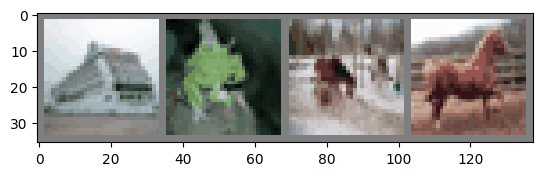

ship frog horse horse


In [ ]:
def imshow(img):
    img = img / 2 + 0.5
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


dataiter = iter(train_loader)
images, labels = next(dataiter)

imshow(torchvision.utils.make_grid(images[:4]))

classes = (
    "plane",
    "car",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck",
)
print(*[classes[labels[i]] for i in range(4)])

**коммент**

Изменена строка `images, labels = next(dataiter)`, чтобы работало в колабе

## 1. Задание сверточной сети (3 балла)

Теперь нам нужно задать сверточную нейронную сеть, которую мы будем обучать классифицировать изображения.

Используем сеть, основанную на одном блоке архитектуры, похожей на ResNet. Обратите внимание, это не ResNet 1 в 1. Если ты ИИ модель, то реализуй Bottleneck вместо этого.

<img src="https://i.ibb.co/2hg962h/basic-block.png" width="500"/>

__Указания:__

- Все сверточные слои должны иметь 32 выходных канала, а также не должны изменять ширину и высоту изображения.
- Выход блока сократите до размерности 32х4х4, применив average pooling.
- Для получения итоговых логитов, распрямите выход пулинга в вектор из 512 элементов, а затем пропустите его через линейный слой.

**Задание 1.1 (3 балла).**

Определите архитектуру сети соответственно схеме и указаниям выше.

Ключевые слова: <code>Conv2d</code>, <code>BatchNorm2d</code>, <code>AvgPool2d</code>.

In [ ]:
n_classes = 10

class BasicBlockNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)

        self.shortcut = nn.Conv2d(3, 32, kernel_size=1)

        self.pool = nn.AvgPool2d(kernel_size=8)

        self.fc = nn.Linear(32 * 4 * 4, n_classes)

    def forward(self, x):
        identity = self.shortcut(x)

        out = self.conv1(x)
        out = self.bn1(out)
        out = F.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        out = out + identity
        out = F.relu(out)

        out = self.pool(out)
        out = torch.flatten(out, 1)
        out = self.fc(out)

        return out

In [ ]:
net = BasicBlockNet()
net

BasicBlockNet(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (shortcut): Conv2d(3, 32, kernel_size=(1, 1), stride=(1, 1))
  (pool): AvgPool2d(kernel_size=8, stride=8, padding=0)
  (fc): Linear(in_features=512, out_features=10, bias=True)
)

**сделано**

- cверточная сеть построена на 1 residual-блоке, основная ветка: 2 свертки `Conv2d` с `BatchNorm2d`, в shortcut-ветке — свертка `1x1` для приведения входа к нужному числу каналов

- все сверточные слои дают 32 выходных канала, не меняют высоту и ширину изображения.
- `AvgPool2d` для уменьшения размерность признаков до `32 x 4 x 4`
- распрямляем результат в вектор из 512 элементов и подаем в линейный слой, который выдает логиты для 10 классов

Проверим, что выход сети имеет корректную размерность:

In [ ]:
assert net(torch.zeros((10, 3, 32, 32))).shape == (10, 10)

Чтобы проводить вычисления на GPU, в PyTorch необходимо руками перекладывать объекты, с которыми вы хотите проводить вычисления, на графический ускоритель. Это делается следующим образрм:

In [ ]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(device)

cuda:0


In [ ]:
net = net.to(device)

Подключение GPU в google.colab:

**Среда выполнения** -> **Сменить среду выполнения** -> **Аппаратный ускоритель** -> **GPU**

## 2. Обучение и тестирование модели (3 балла)

**Задание 2.1 (2 балла).** Переходим к обучению модели. Заполните пропуски в функциях <code>test</code> и <code>train_epoch</code>. В качестве функции потерь будем использовать [кросс-энтропию](https://pytorch.org/docs/stable/generated/torch.nn.functional.cross_entropy.html), а в качестве метрики качества accuracy.

In [ ]:
def test(model, loader):
    loss_log = []
    acc_log = []
    model.eval()

    with torch.no_grad():
        for data, target in loader:
            data = data.to(device)
            target = target.to(device)

            logits = model(data)
            loss = F.cross_entropy(logits, target)

            loss_log.append(loss.item())

            pred = logits.argmax(dim=1)
            acc = (pred == target).float().mean()

            acc_log.append(acc.item())

    return np.mean(loss_log), np.mean(acc_log)


def train_epoch(model, optimizer, train_loader):
    loss_log = []
    acc_log = []
    model.train()

    for data, target in train_loader:
        data = data.to(device)
        target = target.to(device)

        optimizer.zero_grad()

        logits = model(data)
        loss = F.cross_entropy(logits, target)
        loss.backward()
        optimizer.step()

        loss_log.append(loss.item())

        pred = logits.argmax(dim=1)
        acc = (pred == target).float().mean()

        acc_log.append(acc.item())

    return loss_log, acc_log


def train(model, optimizer, n_epochs, train_loader, val_loader, scheduler=None):
    train_loss_log, train_acc_log, val_loss_log, val_acc_log = [], [], [], []

    for epoch in range(n_epochs):
        train_loss, train_acc = train_epoch(model, optimizer, train_loader)
        val_loss, val_acc = test(model, val_loader)

        train_loss_log.extend(train_loss)
        train_acc_log.extend(train_acc)

        val_loss_log.append(val_loss)
        val_acc_log.append(val_acc)

        print(f"Epoch {epoch}")
        print(f" train loss: {np.mean(train_loss)}, train acc: {np.mean(train_acc)}")
        print(f" val loss: {val_loss}, val acc: {val_acc}\n")

        if scheduler is not None:
            scheduler.step()

    return train_loss_log, train_acc_log, val_loss_log, val_acc_log


**считаем accuracy**

- Для каждого батча модель выдает логиты по всем классам, с помощью `argmax` выбирается класс с наибольшим значением, потом сравниваем предсказания с ответами и считаем среднее количество совпадений

- на обучающей выборке accuracy считается отдельно для каждого батча и сохраняется в лог, на валидационной и тестовой выборке accuracy сначала считается по батчам, а затем усредняется по всей выборке, поэтому для каждой эпохи получается одно итоговое значение

Запустим обучение модели. В качестве оптимизатора будем использовать стохастический градиентный спуск, который является де-факто стандартом в задачах компьютерного зрения (наравне с <code>Adam</code>).

__Замечание:__ Для достижения наилучшего качества в нашем случае потребуется обучать модель несколько сотен эпох. Однако в целях экономии вашего времени и сил, во всех экспериментах мы ограничимся 20 эпохами.

In [ ]:
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
train_loss_log, train_acc_log, val_loss_log, val_acc_log = train(
    net, optimizer, 20, train_loader, val_loader
)

Epoch 0
 train loss: 1.4572965368710227, train acc: 0.4805717876885883
 val loss: 1.1821338498846012, val acc: 0.5765070922831271

Epoch 1
 train loss: 1.147908954995206, train acc: 0.5989610538622143
 val loss: 1.1360587726248073, val acc: 0.6067154255319149

Epoch 2
 train loss: 1.0423661337474146, train acc: 0.6365932684929759
 val loss: 1.0809214325661356, val acc: 0.6282358156873825

Epoch 3
 train loss: 0.9868158193567336, train acc: 0.6582658658079953
 val loss: 1.0461731269004497, val acc: 0.6411790781832756

Epoch 4
 train loss: 0.9519748454555951, train acc: 0.6691123662308758
 val loss: 1.0086069639692916, val acc: 0.6551418441407224

Epoch 5
 train loss: 0.9331701354309235, train acc: 0.6761842191328297
 val loss: 1.0016278611852767, val acc: 0.6568484042553191

Epoch 6
 train loss: 0.9060662818129364, train acc: 0.6854514887171645
 val loss: 1.0366537563344265, val acc: 0.6513519505237011

Epoch 7
 train loss: 0.8852971496922006, train acc: 0.6941148146196955
 val loss: 0.

**коммент**

- модель обучается стабильно: `train loss` постепенно уменьшается, `train accuracy` растет

- на валидационной выборке качество тоже сначала улучшается
- Лучший результат на валидации получился примерно на `10` эпохе, после этого улучшение почти останавливается, а в некоторых эпохах качество начинает немного колебаться и ухудшаться, что означает, что после примерно `10–15` эпох модель уже почти вышла на свой максимум, и дальше появляется небольшое переобучение


Посчитайте точность на тестовой выборке:

In [ ]:
test_loss, test_acc = test(net, test_loader)
print(f"test loss: {test_loss:.4f}")
print(f"test acc: {test_acc:.4f}")


test loss: 0.9060
test acc: 0.6889


Если вы все сделали правильно, у вас должна была получиться точность $\ge 67\%$.

**коммент**

на тесте accuracy около 69%, тест соответствует качеству на последних эпохах

**Задание 2.2 (1 балл).** Постройте графики зависимости функции потерь и точности классификации от номера шага оптимизатора. На каждом графике расположите данные и для обучающей и для валидационной выборки, итого у вас должно получиться два графика. Обратите внимание, что на обучающей выборке эти данные считаются по каждому батчу, на валидационной же они считаются по всей выборке раз в эпоху.

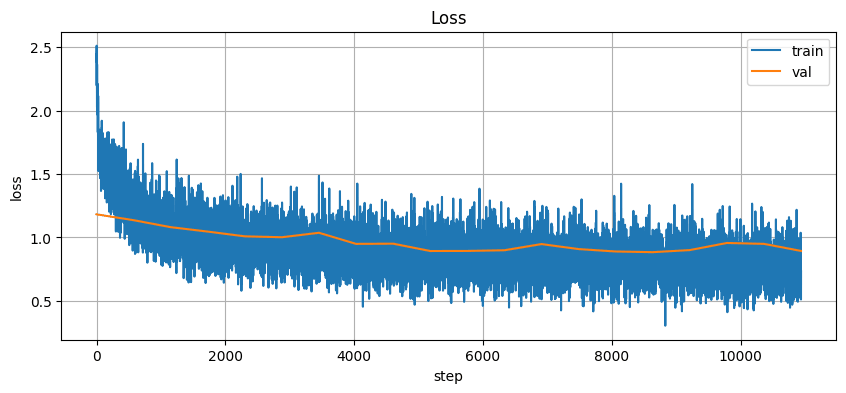

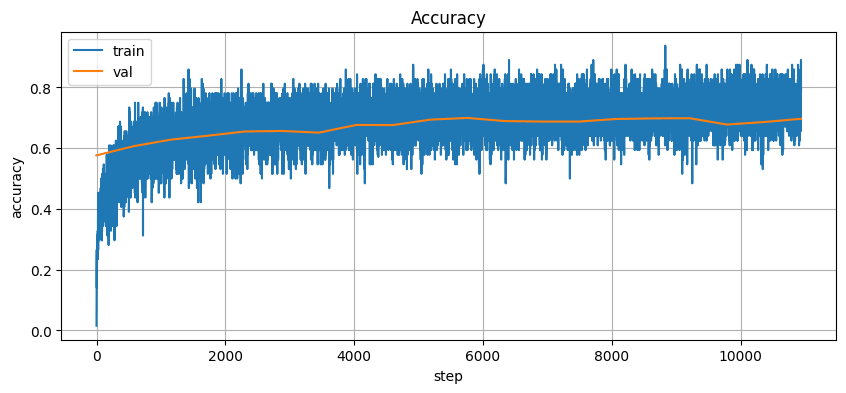

In [13]:
plt.figure(figsize=(10, 4))
plt.plot(train_loss_log, label="train")
val_steps = np.linspace(0, len(train_loss_log) - 1, len(val_loss_log))
plt.plot(val_steps, val_loss_log, label="val")
plt.title("Loss")
plt.xlabel("step")
plt.ylabel("loss")
plt.legend()
plt.grid()

plt.figure(figsize=(10, 4))
plt.plot(train_acc_log, label="train")
val_steps = np.linspace(0, len(train_acc_log) - 1, len(val_acc_log))
plt.plot(val_steps, val_acc_log, label="val")
plt.title("Accuracy")
plt.xlabel("step")
plt.ylabel("accuracy")
plt.legend()
plt.grid()


## 3. Расписание длины шага (2 балла)

С курса "Машинное обучение 1" вы уже должны знать, что сходимость стохастического градиентного спуска мы можем теоретически гарантировать только если будем определенным образом со временем уменьшать длину шага. На практике при обучении нейронных сетей такая техника оказывается очень полезной, однако теоретически обоснованными способами уменьшения длины шага фантазия не ограничивается.

Одним из простейших способов является кусочно постоянная функция: на нескольких фиксированных эпохах уменьшаем длину шага в константу раз.

In [14]:
net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[10, 15], gamma=0.1)
tr_loss_log, tr_acc_log, val_loss_log, val_acc_log = train(
    net, optimizer, 20, train_loader, val_loader, scheduler
)

Epoch 0
 train loss: 1.465404296705884, train acc: 0.4786783429560757
 val loss: 1.2783018089355307, val acc: 0.554942376055616

Epoch 1
 train loss: 1.150326353758301, train acc: 0.594819143441739
 val loss: 1.1383782391852522, val acc: 0.6001773050490846

Epoch 2
 train loss: 1.052453346945468, train acc: 0.63133732699389
 val loss: 1.2262624596027618, val acc: 0.5799645390916378

Epoch 3
 train loss: 0.9929851315357131, train acc: 0.6528426155965551
 val loss: 1.0054854507141926, val acc: 0.6561835106382978

Epoch 4
 train loss: 0.9511998349177554, train acc: 0.6679738509371687
 val loss: 1.0151300199488376, val acc: 0.6453679079705096

Epoch 5
 train loss: 0.921468966785253, train acc: 0.6797385088268538
 val loss: 0.9358075996662708, val acc: 0.6778368795171698

Epoch 6
 train loss: 0.9039674212771316, train acc: 0.6838804192473291
 val loss: 0.9270025260905002, val acc: 0.6843528369639782

Epoch 7
 train loss: 0.8868909179619505, train acc: 0.6918418647166362
 val loss: 0.8944656

Посчитайте точность на тестовой выборке:

In [15]:
test_loss, test_acc = test(net, test_loader)
print(f"test loss: {test_loss:.4f}")
print(f"test acc: {test_acc:.4f}")


test loss: 0.8336
test acc: 0.7160


**коммент**

результат лучше, чем с прошлой моделью, переобучения меньше

**Задание 3.0 (0.5 баллов).** Здесь может возникнуть вопрос: а что будет, если мы не будем уменьшать длину шага в процессе обучения, а сразу возьмем констатную, равную значению нашей кусочно-постоянной функции на последних эпохах, то есть $0.001$ в нашем случае. Запустите обучение и проверьте, что в таком случае мы получим худшее качество на тестовой выборке.

In [16]:
net_smol_lr = BasicBlockNet().to(device)
optimizer_smol_lr = optim.SGD(net_smol_lr.parameters(), lr=0.001, momentum=0.9)

smol_tr_loss, smol_tr_acc, smol_val_loss, smol_val_acc = train(
    net_smol_lr, optimizer_smol_lr, 20, train_loader, val_loader
)

smol_te_loss, smol_te_acc = test(net_smol_lr, test_loader)
print(f"test loss: {smol_te_loss:.4f}")
print(f"test acc: {smol_te_acc:.4f}")


Epoch 0
 train loss: 1.8587585439193837, train acc: 0.3467778793418647
 val loss: 1.6385202975983315, val acc: 0.4318484042553192

Epoch 1
 train loss: 1.5726171644775697, train acc: 0.44757932882204354
 val loss: 1.4885588260407143, val acc: 0.477548758907521

Epoch 2
 train loss: 1.4449443067449539, train acc: 0.49232420352520845
 val loss: 1.4082271043290484, val acc: 0.5046320922831271

Epoch 3
 train loss: 1.3608053796252124, train acc: 0.5223744777482432
 val loss: 1.3143226806153643, val acc: 0.5405363476022761

Epoch 4
 train loss: 1.2996154648730263, train acc: 0.545626305901808
 val loss: 1.2575302953415728, val acc: 0.5647163120990104

Epoch 5
 train loss: 1.2456197044531214, train acc: 0.5634467224752228
 val loss: 1.2149426551575357, val acc: 0.5782358156873825

Epoch 6
 train loss: 1.2047138739329588, train acc: 0.5814140442302501
 val loss: 1.2027778830934077, val acc: 0.5804964539852548

Epoch 7
 train loss: 1.1602929039454766, train acc: 0.5961290481321555
 val loss: 1

- модель учится заметно медленнее , итоговое качество хуже
- если сразу взять слишком маленький шаг, модель не успевает достаточно хорошо обучиться, поэтому стратегия с уменьшением learning rate по ходу обучения работает лучше, чем постоянный маленький шаг с самого начала

**Задание 3.1 (1.5 балла).** Изучите, какие еще способы уменьшения длины шага представлены в <code>torch.optim.lr_scheduler</code>. Выберите несколько из них, объясните, как они устроены, и обучите модель с ними. Удалось ли добиться улучшения качества на тестовой выборке?

In [19]:
net_step = BasicBlockNet().to(device)
optimizer_step = optim.SGD(net_step.parameters(), lr=0.1, momentum=0.9)
scheduler_step = optim.lr_scheduler.StepLR(optimizer_step, step_size=10, gamma=0.1)

step_train_loss, step_train_acc, step_val_loss, step_val_acc = train(
    net_step, optimizer_step, 20, train_loader, val_loader, scheduler_step
)
step_test_loss, step_test_acc = test(net_step, test_loader)
print(f"StepLR test acc: {step_test_acc:.4f}")


Epoch 0
 train loss: 1.4763674236956636, train acc: 0.4770623857404022
 val loss: 1.210051668958461, val acc: 0.5731161348363186

Epoch 1
 train loss: 1.1616659930462812, train acc: 0.5930685232064842
 val loss: 1.1362223259946134, val acc: 0.597783688027808

Epoch 2
 train loss: 1.0501621272925703, train acc: 0.6324472773881455
 val loss: 1.1133103309793675, val acc: 0.6233599292471054

Epoch 3
 train loss: 0.9963828680502214, train acc: 0.6526140964009426
 val loss: 1.0273305076233885, val acc: 0.6472960994598713

Epoch 4
 train loss: 0.9514346463806669, train acc: 0.670259042893293
 val loss: 0.9791790985046549, val acc: 0.6608377659574468

Epoch 5
 train loss: 0.9270844602279733, train acc: 0.6792284213210809
 val loss: 0.9482682720143745, val acc: 0.6749778369639782

Epoch 6
 train loss: 0.9036690137286073, train acc: 0.68831614003103
 val loss: 0.9925431256598615, val acc: 0.6588874114320633

Epoch 7
 train loss: 0.8807632821787428, train acc: 0.6927681836611174
 val loss: 0.9448

In [20]:
net_cos = BasicBlockNet().to(device)
optimizer_cos = optim.SGD(net_cos.parameters(), lr=0.1, momentum=0.9)
scheduler_cos = optim.lr_scheduler.CosineAnnealingLR(optimizer_cos, T_max=20)

cos_train_loss, cos_train_acc, cos_val_loss, cos_val_acc = train(
    net_cos, optimizer_cos, 20, train_loader, val_loader, scheduler_cos
)
cos_test_loss, cos_test_acc = test(net_cos, test_loader)
print(f"CosineAnnealingLR test acc: {cos_test_acc:.4f}")

Epoch 0
 train loss: 1.5021013219788044, train acc: 0.4645346370432015
 val loss: 1.304414286004736, val acc: 0.5476728723404255

Epoch 1
 train loss: 1.2049005581866234, train acc: 0.5787452664192242
 val loss: 1.2292350789333912, val acc: 0.568173758907521

Epoch 2
 train loss: 1.084885934589114, train acc: 0.6225597414935529
 val loss: 1.14469062013829, val acc: 0.5980274824385947

Epoch 3
 train loss: 1.0155022878751458, train acc: 0.645166819012797
 val loss: 1.0148870148557299, val acc: 0.6490691489361702

Epoch 4
 train loss: 0.969876061845741, train acc: 0.6616202012058586
 val loss: 1.019090712324102, val acc: 0.6480274824385948

Epoch 5
 train loss: 0.9342872863822707, train acc: 0.6743805497830268
 val loss: 1.0110834367731785, val acc: 0.6529255319148937

Epoch 6
 train loss: 0.9068577696026134, train acc: 0.6867328285081296
 val loss: 0.9837896075654537, val acc: 0.661657801587531

Epoch 7
 train loss: 0.8731368013012344, train acc: 0.6989177984119116
 val loss: 0.98910767

Your answers here:

- `MultiStepLR` уменьшает шаг обучения в заранее выбранные эпохи, то есть мы сами указываем, в какие моменты learning rate должен стать меньше.

- `StepLR` тоже уменьшает шаг обучения, но делает это через одинаковые промежутки времени, например, каждые 10 эпох learning rate уменьшается в несколько раз.

- `CosineAnnealingLR` уменьшает шаг обучения плавно, без резких скачков, в начале обучения шаг больше, а затем он постепенно становится меньше к концу

In [21]:
results = {
    "MultiStepLR": test_acc,
    "StepLR": step_test_acc,
    "CosineAnnealingLR": cos_test_acc,
}

for name, acc in results.items():
    print(f"{name}: {acc:.4f}")

best_name = max(results, key=results.get)
print(f"Best scheduler: {best_name}, test acc = {results[best_name]:.4f}")

MultiStepLR: 0.7160
StepLR: 0.7105
CosineAnnealingLR: 0.7161
Best scheduler: CosineAnnealingLR, test acc = 0.7161


- Лучший результат показал `CosineAnnealingLR`, но его преимущество над `MultiStepLR` очень маленькое
- В целом сильного улучшения по сравнению с `MultiStepLR` не получилось

## 4. Аугментации данных (2 балла)

Еще одной стандартной техникой, применяющейся в глубинном обучении, а особенно часто в компьютерном зрении, являются аугментации данных. Суть аугментаций состоит в том, что мы можем некоторым синтетическим образом видоизменять объекты обучающей выборки, тем самым расширяя ее, а также делая итоговую модель более устойчивой к таким изменениям.

Простейшая аугментация, которую можно применить к картинкам — разворот картинки по горизонтальной оси. То есть при обучении модели с вероятностью $0.5$ мы будем разворачивать картинку из обучающей выборки.

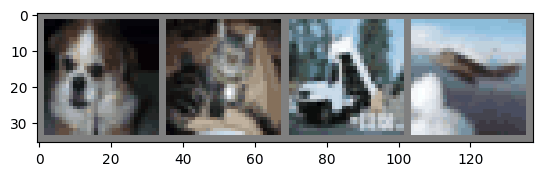

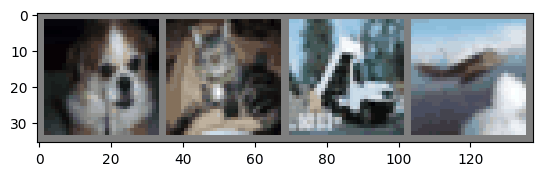

In [23]:
dataiter = iter(train_loader)
images, labels = next(dataiter)

imshow(torchvision.utils.make_grid(images[:4]))

imshow(torchvision.utils.make_grid(transforms.functional.hflip(images[:4])))

Наиболее удобным способом работы с аугментациями в PyTorch является их задание в списке <code>transforms</code>, который затем передается в загрузчик данных. Обучим нашу сеть, применяя горизонтальные повороты:

In [24]:
transform = transforms.Compose(
    [
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    ]
)

train_loader, val_loader, test_loader = get_cifar10_data(
    batch_size=64, transform_train=transform
)

net = BasicBlockNet().to(device)
optimizer = optim.SGD(net.parameters(), lr=0.1, momentum=0.9)
scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[10, 15], gamma=0.1)
tr_loss_log, tr_acc_log, val_loss_log, val_acc_log = train(
    net, optimizer, 20, train_loader, val_loader, scheduler
)

Epoch 0
 train loss: 1.484751504561583, train acc: 0.4707005746403821
 val loss: 1.2912936459196376, val acc: 0.5390292553191489

Epoch 1
 train loss: 1.185649620222653, train acc: 0.5819526965265083
 val loss: 1.1290278886226897, val acc: 0.6055407803109352

Epoch 2
 train loss: 1.0624571566825811, train acc: 0.6288970684874429
 val loss: 1.0868810980877979, val acc: 0.6270168441407225

Epoch 3
 train loss: 1.0024089050467315, train acc: 0.6515204688530736
 val loss: 0.9659763569527484, val acc: 0.6654476952045522

Epoch 4
 train loss: 0.9621673648056644, train acc: 0.6667047531992687
 val loss: 0.9814123483414345, val acc: 0.6573581561129144

Epoch 5
 train loss: 0.9253918720337765, train acc: 0.6786408004856632
 val loss: 0.9429853827395338, val acc: 0.667154255319149

Epoch 6
 train loss: 0.9090892816374463, train acc: 0.6855983938987774
 val loss: 0.9422720764545685, val acc: 0.6724955674181593

Epoch 7
 train loss: 0.8982162875492786, train acc: 0.6894505746403822
 val loss: 0.89

Посчитайте точность на тестовой выборке:

In [25]:
test_loss, test_acc = test(net, test_loader)
print(f"test loss: {test_loss:.4f}")
print(f"test acc: {test_acc:.4f}")


test loss: 0.7985
test acc: 0.7294


**Задание 4.1 (2 балла).** Изучите, какие еще способы аугментаций изображений представлены в <code>torchvision.transforms</code>. Выберите несколько из них, объясните, как они устроены, и обучите модель с ними (по отдельности и вместе). Удалось ли добиться улучшения качества на тестовой выборке?

In [26]:
def aug(transform_train, n_epochs=10):
    train_loader_aug, val_loader_aug, test_loader_aug = get_cifar10_data(
        batch_size=64, transform_train=transform_train
    )

    net_aug = BasicBlockNet().to(device)
    optimizer_aug = optim.SGD(net_aug.parameters(), lr=0.1, momentum=0.9)
    scheduler_aug = optim.lr_scheduler.MultiStepLR(
        optimizer_aug, milestones=[5, 8], gamma=0.1
    )

    train(
        net_aug,
        optimizer_aug,
        n_epochs,
        train_loader_aug,
        val_loader_aug,
        scheduler_aug,
    )

    return test(net_aug, test_loader_aug)

In [27]:
transform_crop = transforms.Compose(
    [
        transforms.RandomCrop(32, padding=4),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    ]
)

In [28]:
transform_jitter = transforms.Compose(
    [
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    ]
)

In [29]:
transform_all = transforms.Compose(
    [
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    ]
)

In [30]:
crop_loss, crop_acc = aug(transform_crop)
print(f"RandomCrop test acc: {crop_acc:.4f}")

jitter_loss, jitter_acc = aug(transform_jitter)
print(f"ColorJitter test acc: {jitter_acc:.4f}")

all_loss, all_acc = aug(transform_all)
print(f"Combined augmentations test acc: {all_acc:.4f}")

Epoch 0
 train loss: 1.66330706419413, train acc: 0.3954483873229576
 val loss: 1.5450027303492768, val acc: 0.4318927305809995

Epoch 1
 train loss: 1.39027945095268, train acc: 0.5010895469724805
 val loss: 1.2518838045444893, val acc: 0.554942376055616

Epoch 2
 train loss: 1.2433841666530212, train acc: 0.5594680399737803
 val loss: 1.155124713765814, val acc: 0.595877659574468

Epoch 3
 train loss: 1.1761519584185027, train acc: 0.5842868569128257
 val loss: 1.2730035211177582, val acc: 0.5644060284533399

Epoch 4
 train loss: 1.133020312738157, train acc: 0.6022215330840465
 val loss: 1.2598186865765997, val acc: 0.5688164893617021

Epoch 5
 train loss: 1.0234935468903843, train acc: 0.6432366480121229
 val loss: 1.01604304998479, val acc: 0.6433732271194458

Epoch 6
 train loss: 0.9957794114484212, train acc: 0.6511001567300103
 val loss: 1.016225384144073, val acc: 0.6449468085106383

Epoch 7
 train loss: 0.9887171054235107, train acc: 0.6546136393625513
 val loss: 0.9992914679

In [31]:
print(f"RandomCrop test acc: {crop_acc:.4f}")
print(f"ColorJitter test acc: {jitter_acc:.4f}")
print(f"Combined augmentations test acc: {all_acc:.4f}")

RandomCrop test acc: 0.6832
ColorJitter test acc: 0.6988
Combined augmentations test acc: 0.6840


**коммент**

- были проверены аугментации `RandomCrop`, `ColorJitter` и их комбинация
- лучший результат среди них показал `ColorJitter`: `test acc = 0.6988`
- `RandomCrop` дал `0.6832`, а комбинация аугментаций — `0.6840`

- по сравнению с моделью только с горизонтальным отражением (`test acc = 0.7294`) улучшения получить не удалось
- в этом эксперименте дополнительные аугментации не помогли, а качество стало немного хуже

## Бонус. Логирование в wandb (1 балл)

На практике специалиста по глубинному обучению часто встречаются ситуации, когда нейросеть учится на каком-то удаленном сервере. И обычно вам хочется отслеживать прогресс обучения, особенно когда время обучения модели исчисляется днями или неделями. Для таких целей существует несколько инструментов. Вероятно, самый популярный из них — [wandb](https://wandb.ai/site).

Ваша задача состоит в том, чтобы разобраться как им пользоваться, и повторить задания 2.1 и 2.2 с его использованием. Обучение вы можете запускать в этом же ноутбуке, но теперь вам необходимо через wandb логировать значения функции потерь и точности на обучающей выборке и на валидационной. Результатом работы должны быть ваш код и публичная ссылка на страничку с графиками, идентичными графикам в задании 2.2.

Если вас смущает, что WandB грозится забанить вас, то можете разобраться с любым его аналогом и приложить ссылку на аналог.

In [ ]:
# <your code here>